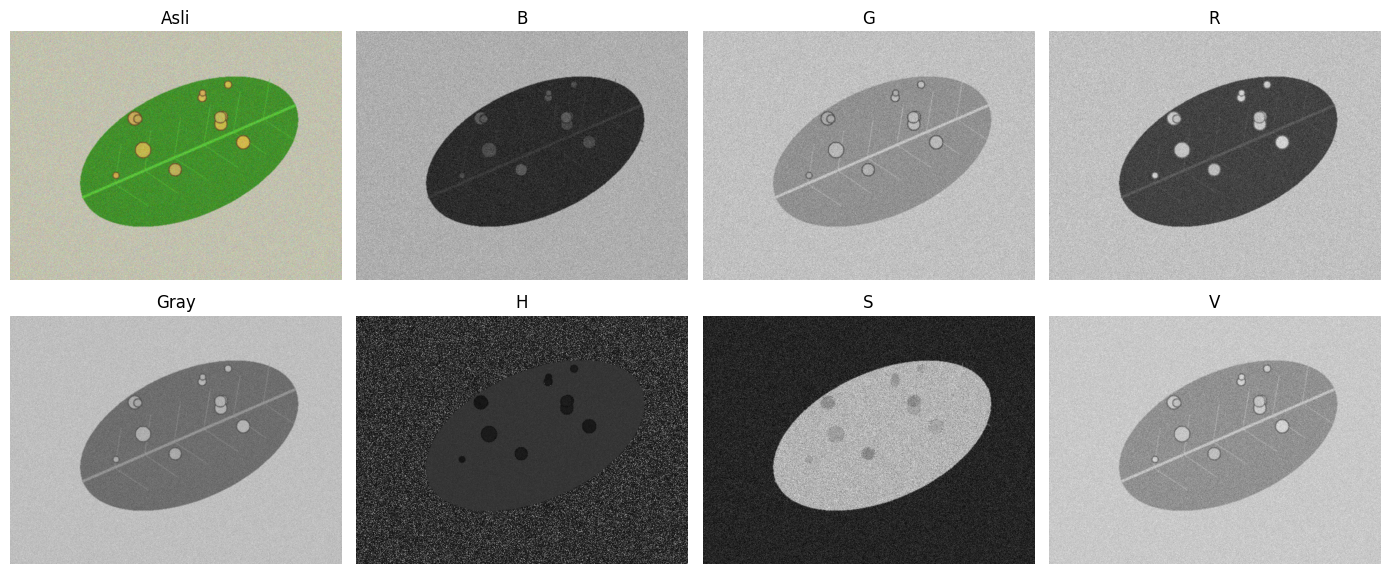

--- NILAI KB PER KANAL (TEH_041) ---
KB kanal B   : 1.71
KB kanal G   : 0.27
KB kanal R   : 7.11
KB kanal Gray: 3.21
KB kanal H   : 5.47
KB kanal S   : 1.11
KB kanal V   : 1.55

--- EKSPERIMEN SAMPLING ---
fx=0.5: ukuran (240, 320), KB=4.33
fx=0.2: ukuran (96, 128), KB=4.27
fx=0.1: ukuran (48, 64), KB=3.00
fx=0.05: ukuran (24, 32), KB=1.61

--- EKSPERIMEN KUANTISASI ---
k=1: 2 level, KB=2.55
k=2: 4 level, KB=2.62
k=3: 7 level, KB=3.16
k=4: 12 level, KB=2.96
k=8: 167 level, KB=3.21

--- MENYUSUN TABEL 8 (RERATA KB KELAS BERAT) ---
                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.30  0.42   6.45  1.86  5.54  1.15  1.01
gelap           1.19  1.34  10.64  4.47  6.14  0.94  3.07
kontras_rendah  0.71  0.28   4.14  2.12  2.37  0.20  1.25
normal          2.41  1.41   9.25  4.83  6.40  1.04  3.05
terang          1.79  0.48   6.10  3.28  4.72  1.05  1.59

Tabel 8 berhasil disimpan di hasil/b2_kb_kanal.csv!


In [15]:
import os
import sys
if os.getcwd().endswith("notebook"):
    os.chdir("..")
sys.path.append("src")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

# ==========================================
# KODE 2.1: Pemisahan Kanal dan Kontras Bercak
# ==========================================
nama = "teh_041.png" # kelas berat, kondisi normal[cite: 21]
img = baca(f"data/sintetis/citra/{nama}")
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))

print("--- NILAI KB PER KANAL (TEH_041) ---")
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

# ==========================================
# KODE 2.2: Sampling dan Kuantisasi
# ==========================================
print("\n--- EKSPERIMEN SAMPLING ---")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

print("\n--- EKSPERIMEN KUANTISASI ---")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2**k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

# ==========================================
# KODE 2.3: Rerata KB per Kanal dan Kondisi (Tabel 8)[cite: 19]
# ==========================================
print("\n--- MENYUSUN TABEL 8 (RERATA KB KELAS BERAT) ---")
def semua_kanal(im_bgr):
    hsv_c = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2HSV)
    bc, gc, rc = cv2.split(im_bgr)
    hc, sc, vc = cv2.split(hsv_c)
    return {"B": bc, "G": gc, "R": rc, "Gray": cv2.cvtColor(im_bgr, cv2.COLOR_BGR2GRAY), "H": hc, "S": sc, "V": vc}

label = pd.read_csv("data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)

# Simpan ke folder hasil
tabel_kb.to_csv("hasil/b2_kb_kanal.csv")
print("\nTabel 8 berhasil disimpan di hasil/b2_kb_kanal.csv!")